# 04 · XAI: atribuciones sobre el MLP de la tarea (a)
Baseline único para todos los métodos: el planeta medio de train (vector cero estandarizado; log para δ y κ). Espacio de salida: logit de P(sobrevive). Cálculo: `python -m worldsim.xai.run_xai`. **La fidelidad contra el simulador queda para la Fase 2.**

In [1]:
import os, sys
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
sys.path.insert(0, "src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.options.display.float_format = "{:.4f}".format

In [2]:
import json
print(json.dumps(json.load(open('outputs/xai/checks.json')), indent=1))
d = np.load('outputs/xai/attributions.npz', allow_pickle=True)
print(str(d['baseline_definition']))
print({k: d[k].shape for k in d.files if k.startswith('phi')})

{
 "checks": {
  "shap_mlp": 5.3797519257159365e-06,
  "ig_mlp": 0.05396270751953125,
  "ig_convergence_delta_max": 0.053966522216796875,
  "treeshap": 3.9076839541962727e-07,
  "exact_vs_kernelshap_max_abs_diff": 3.827636478881402e-07
 }
}
baseline = mean train planet (zero vector in standardised space; log for delta,kappa); output space = logit of P(survive); SHAP exact with single reference; IG straight path; TreeSHAP interventional with the same reference
{'phi_shap_mlp': (7500, 11), 'phi_ig_mlp': (7500, 11), 'phi_treeshap_gb': (7500, 11)}


,SHAP (MLP),Integrated Gradients (MLP),TreeSHAP (LightGBM)
delta,3.4555,3.1445,2.8514
kappa,1.8661,1.8354,1.3464
elite_frac,1.3695,1.1929,0.9661
temp,0.6767,0.5968,0.7589
event_rate,0.5878,0.5331,0.5371
beta,0.5592,0.4405,0.5151
s,0.5407,0.4672,0.4051
event_sev,0.5380,0.5127,0.4602
gamma,0.2192,0.1813,0.2970
water,0.0845,0.0843,0.1175


{'spearman_global_shap_vs_ig': 0.9636363636363637, 'spearman_global_shap_vs_tree': 0.990909090909091, 'mean_local_spearman_shap_vs_ig': 0.8299575757575758, 'mean_local_spearman_shap_mlp_vs_tree': 0.7756901938456521}
fracción de |atribución| en factores accionables: {'SHAP (MLP)': 0.5940808247559034, 'Integrated Gradients (MLP)': 0.6080992221832275, 'TreeSHAP (LightGBM)': 0.5610749056153318}


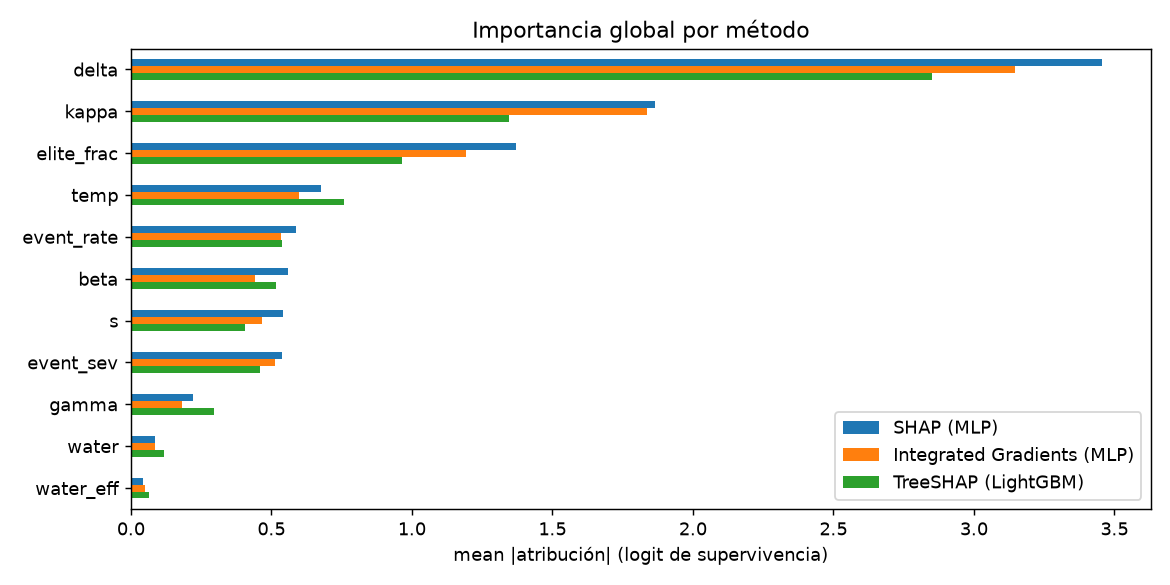

In [3]:
from worldsim.reporting import xai_summary
s = xai_summary(); display(s['importance']); print(s['agreement']); print('fracción de |atribución| en factores accionables:', s['actionable_share'])
display(Image('report/figures/fig_xai_importancia_global.png'))

## Beeswarm (SHAP del MLP)

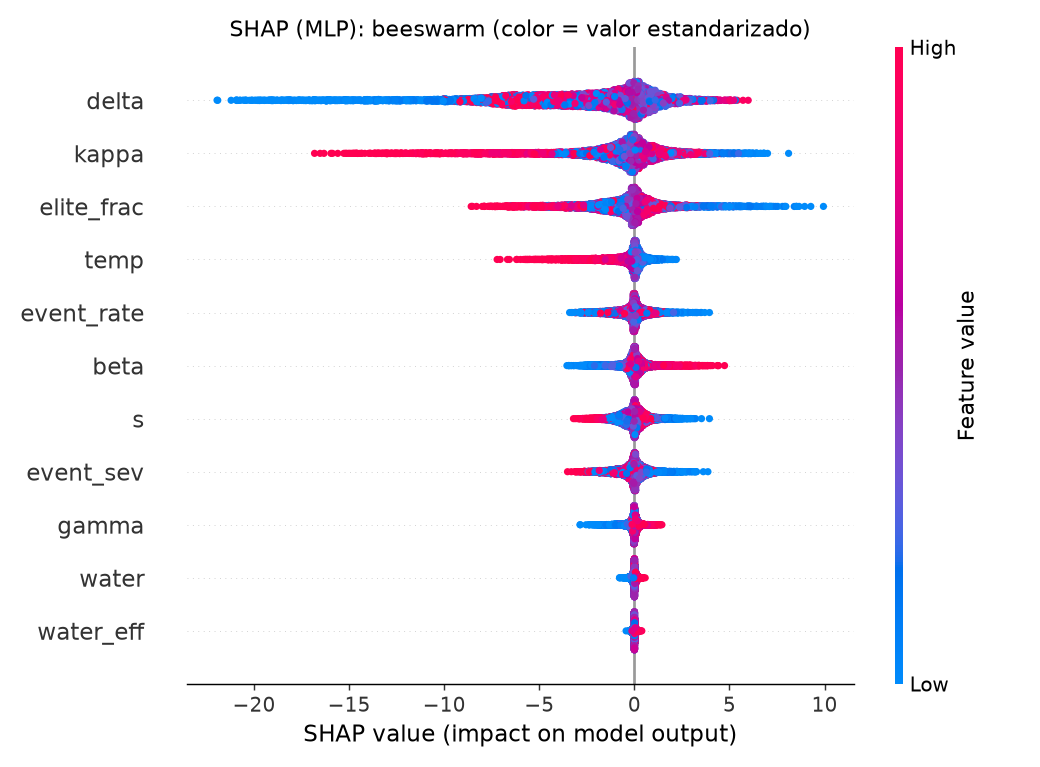

In [4]:
display(Image('report/figures/fig_xai_beeswarm.png'))

## Explicaciones locales (cascada): 2 planetas que sobreviven y 2 que colapsan

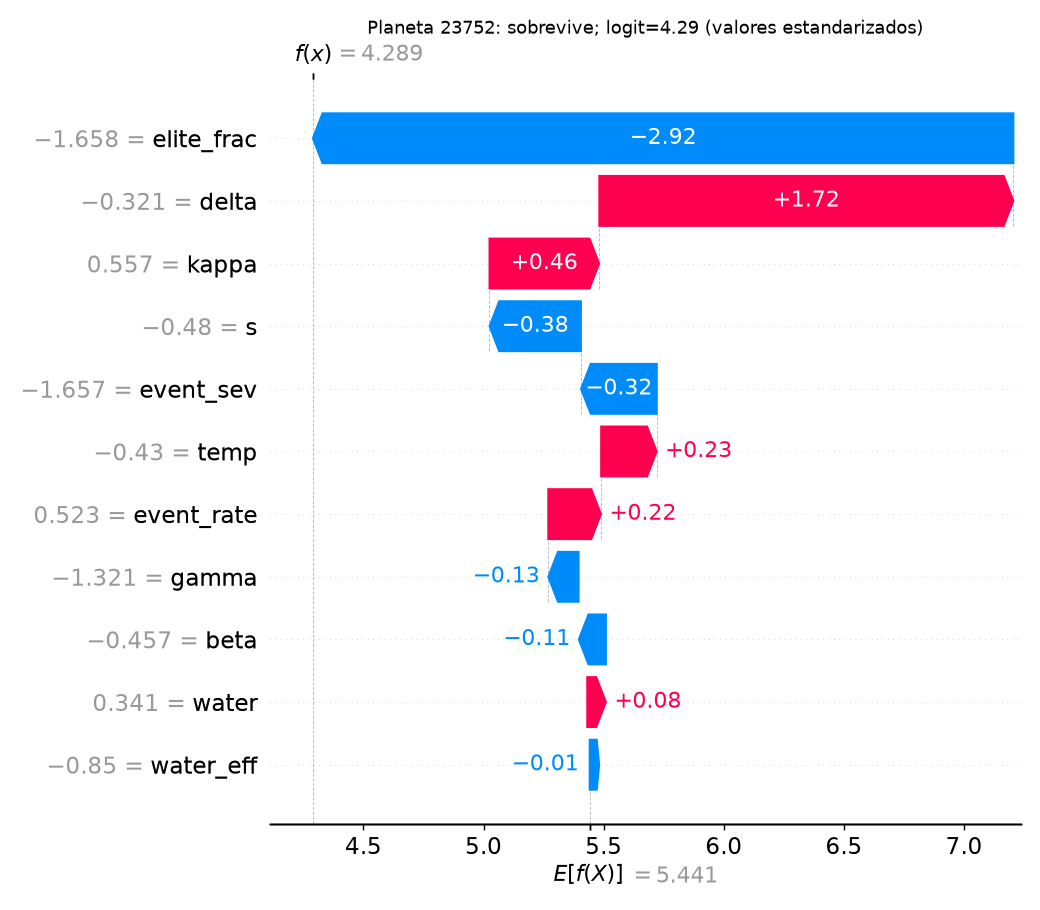

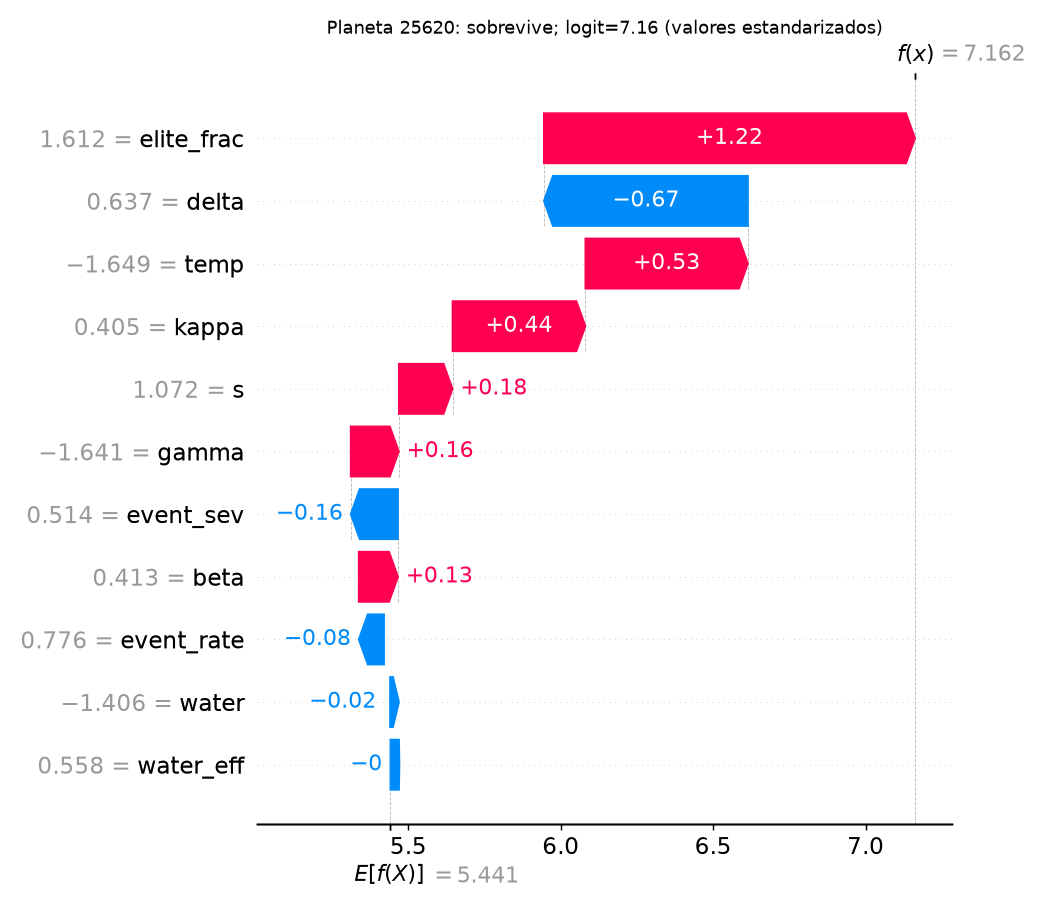

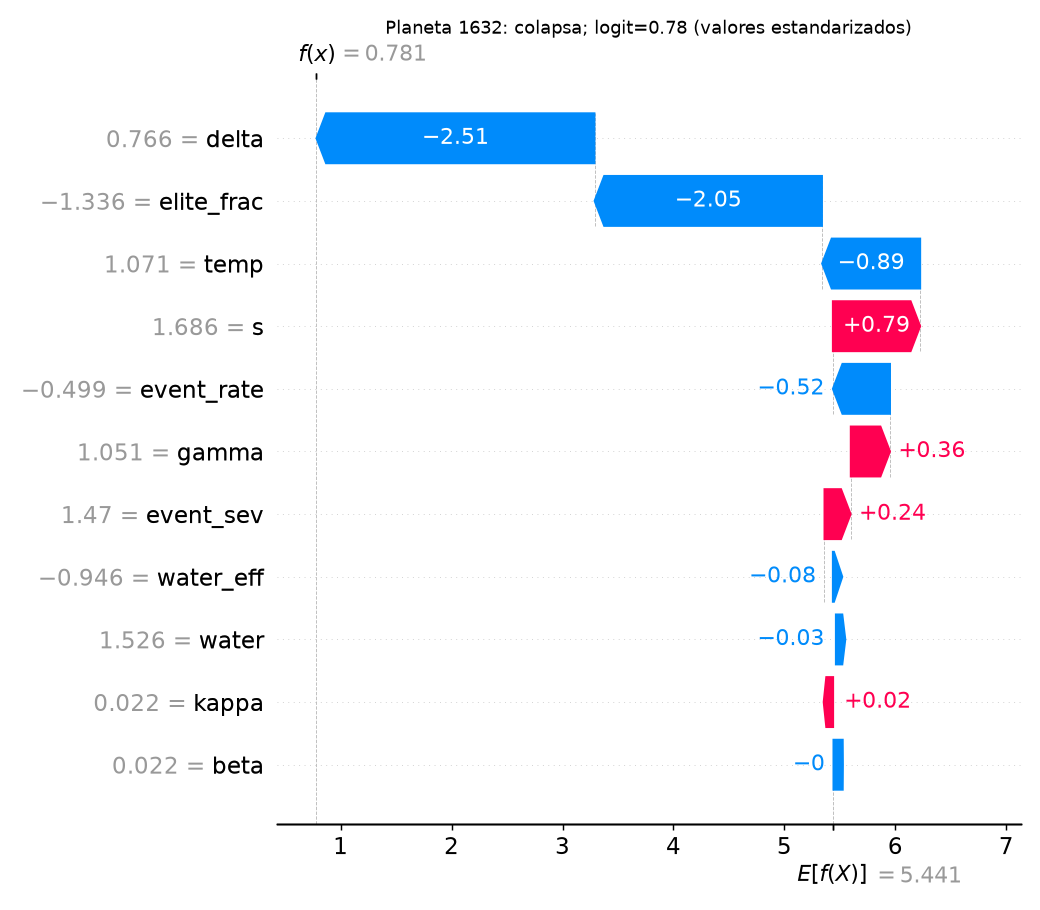

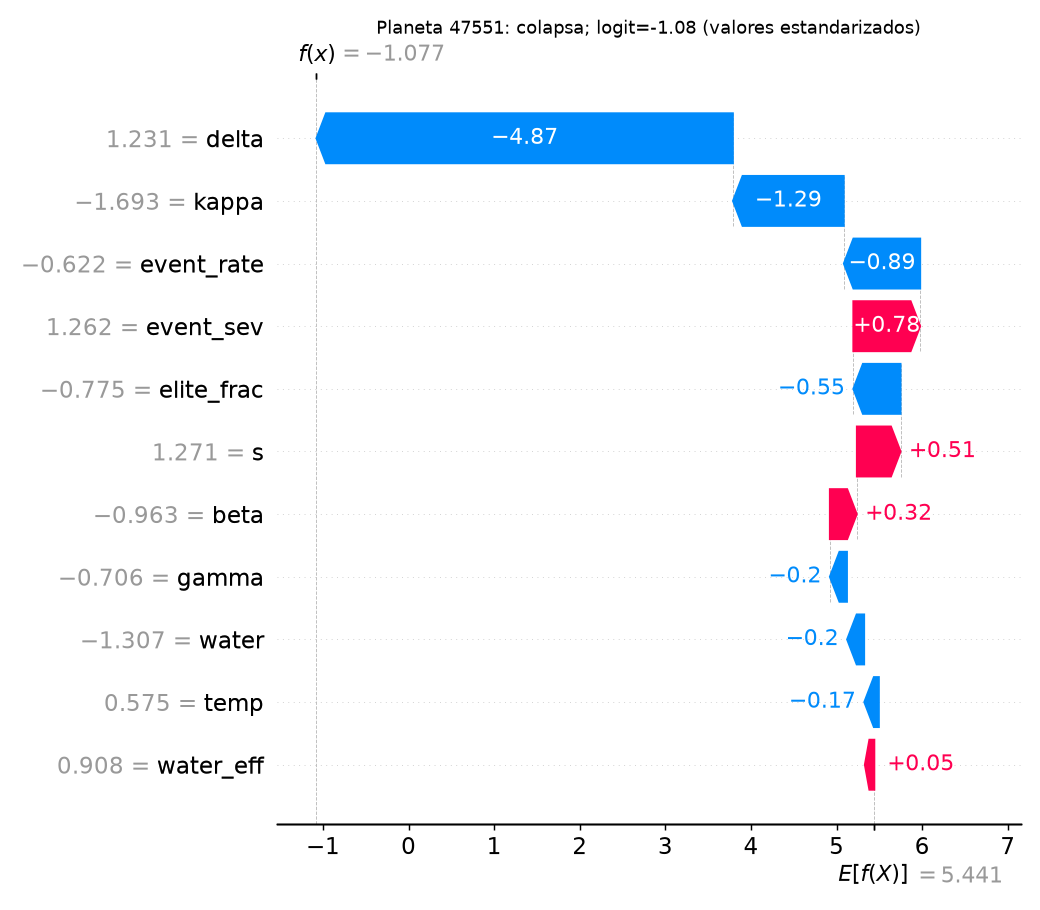

In [5]:
for i in range(1, 5): display(Image(f'report/figures/fig_xai_cascada_{i}.png', width=520))